Collections data analysis

I used this notebook to check the reported 11% recovery improvement and to look through the main data quality issues in the files provided. I have kept the calculations separate from assumptions, because some of the IDs and event fields do not line up cleanly.

The payment comparison below uses successful positive payments after exact duplicate rows are removed. It should be treated as gross payment value, not net settled cash. Run the first cell in Google Colab and upload the project ZIP when prompted.

In [ ]:
from pathlib import Path
import os
import zipfile
from google.colab import files

uploaded = files.upload()
archive_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if archive_name is None:
    raise ValueError("Please upload collections_analytics_assignment_complete.zip")

extract_dir = Path("/content/collections_project")
extract_dir.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(archive_name) as archive:
    archive.extractall(extract_dir)

raw_dir = next((p for p in extract_dir.rglob("raw") if p.is_dir() and p.parent.name == "data"), None)
project_root = raw_dir
if project_root is None:
    raise FileNotFoundError("The ZIP does not contain the expected data/raw folder")
project_root = project_root.parent.parent
os.chdir(project_root)
print("Project folder:", project_root)
print("Raw datasets:", len(list((project_root / "data" / "raw").glob("*.csv"))))

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT/'data'/'raw').exists(): ROOT = Path('../')
RAW = ROOT/'data'/'raw'; OUT = ROOT/'data'/'golden'; OUT.mkdir(exist_ok=True, parents=True)
files = {p.stem: pd.read_csv(p) for p in RAW.glob('*.csv')}
len(files), sorted(files)

(18,
 ['account_status_history',
  'accounts',
  'agent_sessions',
  'agents',
  'borrowers',
  'call_attempts',
  'call_dispositions',
  'calls',
  'campaigns',
  'complaints',
  'daily_targeting',
  'data_dictionary',
  'field_visits',
  'payments',
  'promises_to_pay',
  'sms_events',
  'vendor_telephony',
  'whatsapp_events'])

**1. Source inventory and data quality**

In [2]:
quality=[]
for name,df in files.items():
    quality.append({'dataset':name,'rows':len(df),'columns':len(df.columns),'exact_duplicate_rows':int(df.duplicated().sum()),'missing_cells':int(df.isna().sum().sum()),'missing_pct':100*df.isna().sum().sum()/(len(df)*len(df.columns))})
quality_df=pd.DataFrame(quality).sort_values('dataset')
quality_df

,dataset,rows,columns,exact_duplicate_rows,missing_cells,missing_pct
5,account_status_history,60000,8,0,0,0.000000
0,accounts,30000,11,0,455,0.137879
4,agent_sessions,15000,7,0,0,0.000000
3,agents,30000,8,0,0,0.000000
9,borrowers,30600,8,600,1509,0.616422
10,call_attempts,120000,9,0,2400,0.222222
6,call_dispositions,35000,8,0,0,0.000000
15,calls,91350,11,1271,1827,0.181818
14,campaigns,120,7,0,0,0.000000
8,complaints,8000,9,0,0,0.000000


In [3]:
quality_df.to_csv(OUT/'notebook_dataset_quality.csv',index=False)
print('Total source tables:',len(files),'| Total rows:',sum(len(x) for x in files.values()))

Total source tables: 18 | Total rows: 639328


**2. Timestamp coverage and completeness**

In [4]:
date_rows=[]
for name,df in files.items():
    for col in df.columns:
        if col.endswith('_at') or col.endswith('_date'):
            ts=pd.to_datetime(df[col],errors='coerce')
            if ts.notna().any(): date_rows.append({'dataset':name,'column':col,'valid':int(ts.notna().sum()),'min_source_time':str(ts.min()),'max_source_time':str(ts.max()),'invalid_or_missing':int(ts.isna().sum())})
date_coverage=pd.DataFrame(date_rows); date_coverage

,dataset,column,valid,min_source_time,max_source_time,invalid_or_missing
0,accounts,opened_at,30000,2024-01-01 00:02:27,2025-11-30 23:52:36,0
1,sms_events,event_at,45000,2026-01-01 00:04:16,2026-08-08 23:46:06,0
2,field_visits,event_at,25000,2026-01-01 00:07:53,2026-08-08 23:50:03,0
3,field_visits,scheduled_at,24750,2025-12-31 05:21:55,2026-08-08 21:50:07,250
4,agents,joined_at,30000,2024-01-01 00:10:05,2025-11-30 23:23:30,0
5,agents,updated_at,30000,2025-01-01 00:57:32,2026-08-03 23:45:38,0
6,agent_sessions,login_at,15000,2026-01-01 00:01:57,2026-08-08 23:51:54,0
7,agent_sessions,logout_at,15000,2026-01-01 04:48:48,2026-08-09 07:50:12,0
8,account_status_history,event_at,60000,2026-01-01 00:01:08,2026-08-08 23:50:45,0
9,account_status_history,recorded_at,60000,2025-12-31 01:26:29,2026-08-09 22:02:27,0


**Interpretation.** Main event streams run from 1 January through 8 August 2026. August is partial. Some derived dates extend beyond event coverage: complaint resolutions through 26 August, PTP promised dates through 6 September, and session logout through 9 August. These are outcome/maturity dates, not evidence of additional collection-event months. The 2026-08 partial month must not be compared with full months.

**3. Identity and join integrity**

In [5]:
accounts=files['accounts'].copy()
identity=[]
for name,df in files.items():
    if {'account_id','borrower_id'}.issubset(df.columns):
        j=df[['account_id','borrower_id']].copy()
        m=j.merge(accounts[['account_id','borrower_id']].rename(columns={'borrower_id':'master_borrower_id'}),on='account_id',how='left')
        matched=m.master_borrower_id.notna(); mismatch=matched & m.borrower_id.notna() & (m.borrower_id.astype(str)!=m.master_borrower_id.astype(str))
        identity.append({'dataset':name,'rows':len(df),'matched_account_rows':int(matched.sum()),'orphan_account_rows':int((~matched).sum()),'borrower_mismatch_rows':int(mismatch.sum()),'mismatch_pct':round(100*mismatch.sum()/max(1,(matched&m.borrower_id.notna()).sum()),2)})
identity_df=pd.DataFrame(identity); identity_df

,dataset,rows,matched_account_rows,orphan_account_rows,borrower_mismatch_rows,mismatch_pct
0,accounts,30000,29545,455,0,0.00
1,sms_events,45000,44267,733,44262,99.99
2,field_visits,25000,24623,377,24621,99.99
3,account_status_history,60000,59038,962,59035,99.99
4,call_dispositions,35000,34476,524,34474,99.99
5,payments,25500,25114,386,25113,100.00
6,complaints,8000,7893,107,7892,99.99
7,call_attempts,120000,118137,1863,118126,99.99
8,promises_to_pay,18000,17707,293,17706,99.99
9,calls,91350,89947,1403,89939,99.99


**Decision.** Use `account_id` to connect event rows to the account snapshot. Do not use event borrower IDs for person-level joins: the supplied records show approximately 100% disagreement on matched rows across event datasets. This is a data-integrity defect, not proof that all borrowers are actually different. No borrower-level RPC, contact frequency, or person-level channel attribution is claimed.

**4. Payment reconstruction and headline claim**

In [6]:
payments=files['payments'].copy()
payments['event_dt']=pd.to_datetime(payments.event_at,errors='coerce')
payments['month']=payments.event_dt.dt.to_period('M').astype(str)
pay_clean=payments.drop_duplicates().copy()
monthly=[]
portfolio_n=accounts.account_id.nunique()
for month,g in pay_clean.groupby('month',dropna=True):
    s=g[g.payment_status.astype(str).str.upper().eq('SUCCESS')]
    r=g[g.payment_status.astype(str).str.upper().eq('REVERSED')]
    monthly.append({'month':month,'portfolio_snapshot_accounts':portfolio_n,'success_rows':len(s),'unique_success_payment_ids':s.payment_id.nunique(),'paying_accounts':s.account_id.nunique(),'gross_success_inr':pd.to_numeric(s.amount,errors='coerce').sum(),'reversed_rows':len(r),'reversed_amount_inr':pd.to_numeric(r.amount,errors='coerce').sum(),'payer_rate_snapshot':s.account_id.nunique()/portfolio_n})
monthly_df=pd.DataFrame(monthly).sort_values('month'); monthly_df

,month,portfolio_snapshot_accounts,success_rows,unique_success_payment_ids,paying_accounts,gross_success_inr,reversed_rows,reversed_amount_inr,payer_rate_snapshot
0,2026-01,30000,2464,2464,2374,1.872291e+08,174,11631225.06,0.079133
1,2026-02,30000,2270,2268,2173,1.702796e+08,140,11477682.67,0.072433
2,2026-03,30000,2527,2524,2419,1.891903e+08,187,14372369.75,0.080633
3,2026-04,30000,2407,2406,2304,1.752289e+08,177,13327361.41,0.076800
4,2026-05,30000,2450,2449,2344,1.843355e+08,160,12690920.44,0.078133
5,2026-06,30000,2369,2366,2286,1.758534e+08,173,12949477.35,0.076200
6,2026-07,30000,2442,2441,2335,1.872478e+08,199,15266393.46,0.077833
7,2026-08,30000,616,616,608,4.710970e+07,45,2959050.67,0.020267


In [7]:
full=monthly_df[monthly_df.month< '2026-08'].copy()
full['mom_recovery_pct']=full.gross_success_inr.pct_change()*100
full['mom_payer_rate_pp']=full.payer_rate_snapshot.diff()*100
full

,month,portfolio_snapshot_accounts,success_rows,unique_success_payment_ids,paying_accounts,gross_success_inr,reversed_rows,reversed_amount_inr,payer_rate_snapshot,mom_recovery_pct,mom_payer_rate_pp
0,2026-01,30000,2464,2464,2374,1.872291e+08,174,11631225.06,0.079133,NaN,NaN
1,2026-02,30000,2270,2268,2173,1.702796e+08,140,11477682.67,0.072433,-9.052818,-0.670000
2,2026-03,30000,2527,2524,2419,1.891903e+08,187,14372369.75,0.080633,11.105681,0.820000
3,2026-04,30000,2407,2406,2304,1.752289e+08,177,13327361.41,0.076800,-7.379551,-0.383333
4,2026-05,30000,2450,2449,2344,1.843355e+08,160,12690920.44,0.078133,5.196946,0.133333
5,2026-06,30000,2369,2366,2286,1.758534e+08,173,12949477.35,0.076200,-4.601411,-0.193333
6,2026-07,30000,2442,2441,2335,1.872478e+08,199,15266393.46,0.077833,6.479478,0.163333


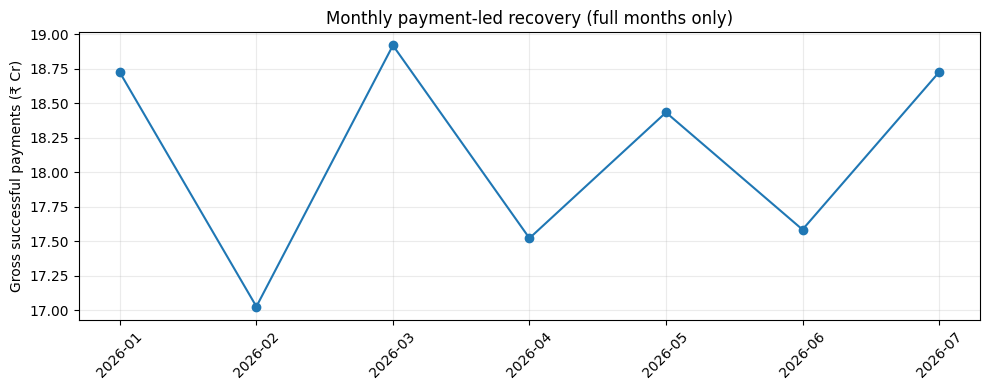

In [8]:
fig,ax=plt.subplots(figsize=(10,4)); ax.plot(full.month,full.gross_success_inr/1e7,marker='o'); ax.set_ylabel('Gross successful payments (₹ Cr)'); ax.set_title('Monthly payment-led recovery (full months only)'); ax.tick_params(axis='x',rotation=45); ax.grid(alpha=.25); plt.tight_layout()

**Metric definition.** Recovery = sum of positive-amount rows with `payment_status=SUCCESS`, after exact full-row duplicate removal. This is gross successful payment value, not net cash recovery, because reversal-to-original linkage is unreliable. Payer rate = unique paying account IDs / 30,000 current account-master snapshot accounts; it is a proxy, not a historical active-account denominator.

**Headline result (Fact).** July gross successful payment value is ₹18.7248 Cr versus June ₹17.5853 Cr: **+6.48%**, not +11%. July is only **+0.01%** versus January. Payer rate rises from 7.62% in June to 7.78% in July, but remains below January's 7.91%. The reported 11% is not reproducible under this independent definition. This does not prove the company's own metric is false until its numerator, denominator, adjustment rules and comparison window are supplied.

**5. Payment forensic checks**

In [9]:
payment_audit={
 'raw_rows':len(payments),'exact_duplicate_rows':int(payments.duplicated().sum()),
 'rows_after_exact_dedup':len(pay_clean),'missing_reference_rows':int(pay_clean.payment_reference.isna().sum()),
 'null_payment_id_rows':int(pay_clean.payment_id.isna().sum())}
ref=pay_clean[pay_clean.payment_reference.notna()].groupby('payment_reference').agg(rows=('payment_id','size'),accounts=('account_id','nunique'),amounts=('amount','nunique'),statuses=('payment_status','nunique')).reset_index()
ref_collisions=ref[ref.rows>1].sort_values('rows',ascending=False)
payment_audit, ref_collisions.head(10)

({'raw_rows': 25500,
  'exact_duplicate_rows': 486,
  'rows_after_exact_dedup': 25014,
  'missing_reference_rows': 382,
  'null_payment_id_rows': 0},
       payment_reference  rows  accounts  amounts  statuses
 13081     TXN0000044312     5         5        5         2
 1993      TXN0000006936     4         4        4         3
 11022     TXN0000037402     4         4        4         3
 17120     TXN0000058005     4         4        4         2
 15649     TXN0000052986     4         4        4         3
 18924     TXN0000063848     4         4        4         1
 6280      TXN0000021482     4         4        4         2
 11043     TXN0000037460     4         4        4         3
 19524     TXN0000065723     4         4        4         3
 9603      TXN0000032669     4         4        4         1)

**Treatment.** Exact duplicate full rows are removed. Payment reference is not treated as a unique key: collisions across accounts, amounts and statuses mean deduplicating on it could delete real transactions. Reversed rows are reported separately and not netted. Production reconciliation requires processor transaction ID, original-transaction reference, reversal linkage, settlement date and idempotency key.

**6. Calls, attempt pressure and disposition taxonomy**

In [10]:
calls=files['calls'].copy(); calls['month']=pd.to_datetime(calls.event_at,errors='coerce').dt.to_period('M').astype(str)
call_summary=calls.groupby(['month','call_status'],dropna=False).agg(rows=('call_id','size'),unique_call_ids=('call_id','nunique'),accounts=('account_id','nunique'),duration_seconds=('duration_sec','sum')).reset_index()
attempts=files['call_attempts'].copy(); attempts['month']=pd.to_datetime(attempts.event_at,errors='coerce').dt.to_period('M').astype(str)
attempt_summary=attempts.groupby(['month','attempt_status'],dropna=False).size().rename('attempts').reset_index()
disposition_summary=files['call_dispositions'].groupby(['disposition_version','disposition_code'],dropna=False).size().rename('rows').reset_index()
call_summary.head(20), attempt_summary.head(20), disposition_summary

(      month call_status  rows  unique_call_ids  accounts  duration_seconds
 0   2025-12      FAILED     1                1         1               851
 1   2026-01    ANSWERED  2588             2543      2433           1168090
 2   2026-01        BUSY  2644             2600      2493           1186936
 3   2026-01      FAILED  2554             2514      2410           1155225
 4   2026-01   NO_ANSWER  2504             2460      2373           1132353
 5   2026-01   VOICEMAIL  2606             2566      2456           1184798
 6   2026-02    ANSWERED  2311             2279      2188           1045150
 7   2026-02        BUSY  2262             2241      2152           1014193
 8   2026-02      FAILED  2399             2353      2253           1062055
 9   2026-02   NO_ANSWER  2423             2379      2280           1092314
 10  2026-02   VOICEMAIL  2345             2318      2230           1072026
 11  2026-03    ANSWERED  2596             2567      2457           1186382
 12  2026-03

**Interpretation.** `ANSWERED` is only an answered-call proxy; it is not RPC because the dataset lacks a validated right-party indicator. `PROMISE_TO_PAY` and `PTP` both occur in disposition codes, so legacy/v1/v2 mappings must be versioned before PTP rates are compared. `call_id` repeats; event-level deduplication cannot safely assume it is unique.

**7. PTP lifecycle and promise-kept analysis**

In [11]:
ptp=files['promises_to_pay'].copy(); ptp['month']=pd.to_datetime(ptp.event_at,errors='coerce').dt.to_period('M').astype(str)
ptp_summary=ptp.groupby(['month','status'],dropna=False).agg(ptp_rows=('ptp_id','size'),ptp_ids=('ptp_id','nunique'),promised_amount=('promised_amount','sum')).reset_index()
ptp_summary

,month,status,ptp_rows,ptp_ids,promised_amount
0,2026-01,BROKEN,644,644,31958689.32
1,2026-01,CANCELLED,619,619,30381438.20
2,2026-01,KEPT,607,607,30332374.66
3,2026-01,OPEN,652,652,33425675.79
4,2026-02,BROKEN,551,551,27627258.38
5,2026-02,CANCELLED,552,552,27258205.50
6,2026-02,KEPT,567,567,29353155.46
7,2026-02,OPEN,550,550,27145775.71
8,2026-03,BROKEN,629,629,31295727.46
9,2026-03,CANCELLED,656,656,33007672.01


**Definition limitation.** Kept PTP rate should use matured promises only: kept / (kept + broken), with OPEN excluded and CANCELLED handled according to a documented cancellation policy. A robust measure also links actual payments to each promise by account and promised date. Since borrower IDs and payment references are unreliable and PTP IDs/status semantics are not independently reconciled, status-based rates are descriptive only—not a verified cash-kept rate.

**8. SMS and WhatsApp event funnels**

In [12]:
def digital_funnel(name):
    d=files[name].copy(); d['month']=pd.to_datetime(d.event_at,errors='coerce').dt.to_period('M').astype(str)
    return d.groupby(['month','event_type'],dropna=False).agg(events=(d.columns[0],'size'),accounts=('account_id','nunique')).reset_index()
sms_funnel=digital_funnel('sms_events'); wa_funnel=digital_funnel('whatsapp_events')
sms_funnel.head(24), wa_funnel.head(30)

(      month event_type  events  accounts
 0   2026-01    CLICKED    1545      1515
 1   2026-01  DELIVERED    1571      1526
 2   2026-01     FAILED    1653      1612
 3   2026-01       SENT    1590      1558
 4   2026-02    CLICKED    1444      1409
 5   2026-02  DELIVERED    1464      1438
 6   2026-02     FAILED    1459      1423
 7   2026-02       SENT    1447      1409
 8   2026-03    CLICKED    1585      1543
 9   2026-03  DELIVERED    1585      1551
 10  2026-03     FAILED    1542      1509
 11  2026-03       SENT    1650      1604
 12  2026-04    CLICKED    1600      1554
 13  2026-04  DELIVERED    1474      1432
 14  2026-04     FAILED    1550      1510
 15  2026-04       SENT    1483      1447
 16  2026-05    CLICKED    1552      1521
 17  2026-05  DELIVERED    1643      1592
 18  2026-05     FAILED    1524      1495
 19  2026-05       SENT    1643      1601
 20  2026-06    CLICKED    1487      1456
 21  2026-06  DELIVERED    1548      1508
 22  2026-06     FAILED    1507   

**Interpretation.** SMS events include SENT, DELIVERED, CLICKED and FAILED; WhatsApp includes SENT, DELIVERED, READ, REPLIED, PAYMENT_CLICK and FAILED. Event counts are not unique borrower conversions. A proper funnel needs message_id lifecycle deduplication, provider delivery receipts, account identity bridge, click-to-payment attribution window and randomized holdout. Do not compare channel conversion from raw event counts.

**9. Field operations**

In [13]:
field=files['field_visits'].copy()
field_summary=field.groupby(['visit_type','outcome'],dropna=False).agg(visits=('visit_id','size'),unique_visits=('visit_id','nunique'),accounts=('account_id','nunique')).reset_index()
field_summary

,visit_type,outcome,visits,unique_visits,accounts
0,AFTER_HOURS,CONTACTED,1065,1065,1042
1,AFTER_HOURS,NOT_AVAILABLE,1042,1042,1029
2,AFTER_HOURS,PAID,1012,1012,998
3,AFTER_HOURS,PTP,1013,1013,996
4,AFTER_HOURS,REFUSED,1033,1033,1018
5,AFTER_HOURS,WRONG_ADDRESS,1027,1027,1015
6,FIRST_VISIT,CONTACTED,1036,1036,1026
7,FIRST_VISIT,NOT_AVAILABLE,1013,1013,989
8,FIRST_VISIT,PAID,1048,1048,1028
9,FIRST_VISIT,PTP,1062,1062,1037


**Interpretation.** `PAID` and `PTP` are visit outcomes but are not independently matched to payment settlement or PTP lifecycle. Visit outcome counts are operational descriptions, not incremental field recovery. Geospatial coordinates may be incomplete and should not be used for agent routing until consent, accuracy and data governance are checked.

**10. Campaign and targeting consistency**

In [14]:
target=files['daily_targeting'].copy(); campaigns=files['campaigns'].copy()
tc=target.merge(campaigns[['campaign_id','channel','strategy_version','target_definition']],on='campaign_id',how='left',suffixes=('_recommended','_campaign'))
campaign_crosswalk=tc.groupby(['recommended_channel','channel','strategy_version'],dropna=False).size().rename('target_rows').reset_index()
strategy_mix=campaigns.groupby(['channel','strategy_version','target_definition'],dropna=False).size().rename('campaign_definitions').reset_index()
campaign_crosswalk.head(30), strategy_mix.head(30)

(   recommended_channel   channel strategy_version  target_rows
 0                FIELD     FIELD           legacy          562
 1                FIELD     FIELD               v1          386
 2                FIELD     FIELD               v2          474
 3                FIELD     FIELD               v3          288
 4                FIELD     MIXED           legacy          607
 5                FIELD     MIXED               v1          493
 6                FIELD     MIXED               v2          577
 7                FIELD     MIXED               v3          546
 8                FIELD       SMS           legacy          889
 9                FIELD       SMS               v1          373
 10               FIELD       SMS               v2          654
 11               FIELD       SMS               v3          730
 12               FIELD     VOICE           legacy          495
 13               FIELD     VOICE               v1          367
 14               FIELD     VOICE       

**Finding.** The recommended channel on daily targeting does not consistently match the campaign table channel; campaign channel includes MIXED and versioned definitions. Therefore a campaign-level channel label is not proof of the channel actually delivered. The data does not contain a clean treatment exposure table tying a unique account to the exact message/call/visit and subsequent payment.

**11. Vendor, agent identity and session feasibility**

In [15]:
agents=files['agents']; agent_audit=agents.groupby('agent_id').agg(rows=('agent_id','size'),employee_codes=('employee_code','nunique'),names=('agent_name','nunique'),vendors=('vendor_id','nunique'),teams=('team','nunique')).reset_index()
agent_audit.query('employee_codes>1 or names>1 or vendors>1 or teams>1').head(20), {'agent_rows':len(agents),'unique_agent_ids':agents.agent_id.nunique(),'unique_employee_codes':agents.employee_code.nunique()}
sessions=files['agent_sessions'].copy(); sessions['login']=pd.to_datetime(sessions.login_at,errors='coerce'); sessions['logout']=pd.to_datetime(sessions.logout_at,errors='coerce'); sessions['session_hours']=(sessions.logout-sessions.login).dt.total_seconds()/3600
sessions.groupby('channel').session_hours.agg(['count','mean','median','min','max'])

,count,mean,median,min,max
channel,,,,,
FIELD,3796,5.239265,5.204583,0.502222,9.998333
SMS,3654,5.270399,5.248333,0.503056,9.998056
VOICE,3740,5.285927,5.238472,0.500000,9.997222
WHATSAPP,3810,5.237594,5.244861,0.502778,9.995000


**Interpretation.** Agent IDs map to multiple employee codes, names, vendors and teams. Agent productivity and tenure ranking are not reliable. Session durations are arithmetic over source timestamps; timezone, overnight session and device/session identity semantics need validation. Vendor comparisons are confounded by routing mix, timezone and vendor mapping changes.

**12. Risk segment and DPD mix — association, not causal effect**

In [16]:
acc_cols=['account_id','dpd','risk_segment','loan_type','outstanding_amount']
account_snapshot=accounts[acc_cols].drop_duplicates('account_id')
account_month=account_snapshot.merge(pay_clean[pay_clean.payment_status.eq('SUCCESS')].groupby(['account_id','month'],as_index=False).amount.sum().rename(columns={'amount':'gross_success_inr'}),on='account_id',how='left')
account_month['gross_success_inr']=account_month.gross_success_inr.fillna(0)
account_month['dpd_band']=pd.cut(pd.to_numeric(account_month.dpd,errors='coerce'),[-1,0,30,60,90,180,365,100000],labels=['Current','1-30','31-60','61-90','91-180','181-365','365+'])
segment_summary=account_month.groupby(['risk_segment','month'],dropna=False).agg(accounts=('account_id','nunique'),gross_recovery=('gross_success_inr','sum'),payers=('gross_success_inr',lambda x:(x>0).sum())).reset_index()
dpd_summary=account_month.groupby(['dpd_band','month'],dropna=False,observed=False).agg(accounts=('account_id','nunique'),gross_recovery=('gross_success_inr','sum'),payers=('gross_success_inr',lambda x:(x>0).sum())).reset_index()
segment_summary.head(30), dpd_summary.head(30)

(   risk_segment    month  accounts  gross_recovery  payers
 0          HIGH  2026-01       607     48244020.67     607
 1          HIGH  2026-02       518     41641034.13     518
 2          HIGH  2026-03       590     48172166.00     590
 3          HIGH  2026-04       533     41506700.79     533
 4          HIGH  2026-05       624     49418274.61     624
 5          HIGH  2026-06       576     45039062.44     576
 6          HIGH  2026-07       580     44438757.09     580
 7          HIGH  2026-08       163     13330659.19     163
 8          HIGH      NaN      4252            0.00       0
 9           LOW  2026-01       589     45440930.21     589
 10          LOW  2026-02       532     41989569.24     532
 11          LOW  2026-03       624     47079655.67     624
 12          LOW  2026-04       636     47129038.77     636
 13          LOW  2026-05       593     45686818.57     593
 14          LOW  2026-06       586     43700273.69     586
 15          LOW  2026-07       599     

**Caveat.** DPD and risk segment are from a current account snapshot. Applying them retrospectively to all months can misclassify historical portfolio mix. These cuts are exploratory associations only; a true mix decomposition needs effective-dated monthly DPD, balance, risk and account eligibility snapshots.

**13. Complaints, account status history and safety guardrails**

In [17]:
complaints=files['complaints'].copy(); complaints['event_dt']=pd.to_datetime(complaints.event_at,errors='coerce'); complaints['resolution_dt']=pd.to_datetime(complaints.resolution_at,errors='coerce'); complaints['resolution_hours']=(complaints.resolution_dt-complaints.event_dt).dt.total_seconds()/3600
complaint_summary=complaints.groupby(['complaint_type','severity','status'],dropna=False).agg(complaints=('complaint_id','nunique'),median_resolution_hours=('resolution_hours','median')).reset_index()
status=files['account_status_history'].copy(); status['event_dt']=pd.to_datetime(status.event_at,errors='coerce'); status['recorded_dt']=pd.to_datetime(status.recorded_at,errors='coerce'); status['recording_lag_hours']=(status.recorded_dt-status.event_dt).dt.total_seconds()/3600
status_summary=status.groupby(['status','source'],dropna=False).agg(events=('history_id','nunique'),accounts=('account_id','nunique'),median_recording_lag_hours=('recording_lag_hours','median')).reset_index()
complaint_summary.head(25), status_summary

(     complaint_type  severity  ... complaints  median_resolution_hours
 0   AGENT_BEHAVIOUR  CRITICAL  ...         65                    240.0
 1   AGENT_BEHAVIOUR  CRITICAL  ...         70                    192.0
 2   AGENT_BEHAVIOUR  CRITICAL  ...         84                    240.0
 3   AGENT_BEHAVIOUR  CRITICAL  ...         66                    240.0
 4   AGENT_BEHAVIOUR      HIGH  ...         77                    192.0
 5   AGENT_BEHAVIOUR      HIGH  ...         87                    240.0
 6   AGENT_BEHAVIOUR      HIGH  ...         87                    264.0
 7   AGENT_BEHAVIOUR      HIGH  ...         80                    240.0
 8   AGENT_BEHAVIOUR       LOW  ...         80                    264.0
 9   AGENT_BEHAVIOUR       LOW  ...         72                    252.0
 10  AGENT_BEHAVIOUR       LOW  ...         77                    216.0
 11  AGENT_BEHAVIOUR       LOW  ...         69                    288.0
 12  AGENT_BEHAVIOUR    MEDIUM  ...         70                  

**Interpretation.** Complaints include harassment, privacy, DND, agent behaviour and disputes; these are guardrail metrics, not merely operational noise. Contact strategy must respect DND, disputes and complaint restrictions. Status history has both event and recorded timestamps; use event time for business-effective status and recorded time for ingestion-lag monitoring, while preserving both.

**14. Statistical threats and what can/cannot be concluded**

| Threat | Evidence available | Conclusion |
|---|---|---|
| Portfolio mix | Current snapshot risk/DPD only | Historical mix effect not identified |
| Cohort effects | Account opened_at and event dates | Can build origination cohorts, but account snapshot/status history must be checked; not causal |
| Selection bias | Targeting rows only; no complete eligible population history | Not identified; targeted vs untargeted comparison is biased |
| Survivorship bias | Current account master may omit closed/removed history | Material risk; historical denominator unavailable |
| Simpson's paradox | Segment cuts possible only using current segment labels | Cannot claim or rule out without effective-dated strata |
| Attribution-window bias | No validated interaction-to-payment mapping/window | Channel/campaign credit not estimable |
| Time-series effects | Jan–Jul complete monthly payments; only 7 points | Descriptive trend only; no robust seasonality/causal break test |

A valid counterfactual should randomize eligible accounts at account level, stratify by pre-treatment DPD/risk/loan type/region, assign treatment vs holdout, keep channel exposure logs, use net settled cash over a pre-registered 30/60/90-day window, and analyze intention-to-treat. If historical targeting rollout dates and comparable untreated groups exist, difference-in-differences can be a secondary design after checking parallel trends.

**15. Investment recommendation and sensitivity**

In [18]:
avg_monthly_gross=full.gross_success_inr.mean()
scenarios=[]
for uplift in [0,0.005,0.01,0.02]:
    incremental_month=avg_monthly_gross*uplift
    annual_increment=incremental_month*12
    pilot_cost=10_000_000
    scenarios.append({'uplift_assumption':uplift,'incremental_monthly_inr':incremental_month,'incremental_annual_inr':annual_increment,'simple_payback_months':pilot_cost/incremental_month if incremental_month>0 else np.inf,'annual_gross_roi_pct':(annual_increment-pilot_cost)/pilot_cost*100})
pd.DataFrame(scenarios), avg_monthly_gross

(   uplift_assumption  ...  annual_gross_roi_pct
 0              0.000  ...           -100.000000
 1              0.005  ...              8.802694
 2              0.010  ...            117.605389
 3              0.020  ...            335.210778
 
 [4 rows x 5 columns],
 np.float64(181337824.11857143))

**Decision.** Recommend only a capped, randomized better-targeting pilot, not immediate deployment of the full ₹10 Cr. The 0.5%, 1% and 2% uplift levels are scenario assumptions, not measured effect sizes. ROI shown is gross and excludes ongoing platform, messaging, agent, compliance and implementation costs. The investment decision should be gated on statistically credible incremental net recovery and complaint/DND guardrails.

**16. Final conclusion and follow-up data requirements**

1. **What happened?** July gross successful payment value rose 6.48% month-on-month, not 11%, under the independent payment-led definition. It was essentially flat versus January. August is partial.
2. **Why?** The extract does not support causal attribution to channel, campaign, vendor, agent or targeting. Key identity, payment and timestamp defects block this.
3. **Confidence.** Moderate for exact-row-deduplicated gross successful payment totals; low for net cash, borrower-level, agent-level, channel and causal conclusions.
4. **What next?** Reconcile processor transactions and reversals; build effective-dated account/borrower/agent crosswalks; normalize timezone with source-system documentation; maintain monthly eligible-account snapshots; run randomized targeting holdout.
5. **Required additional data.** Settlement/transaction IDs and reversal linkage; historical account balance/DPD snapshots; eligibility and targeting exposure logs; right-party contact flags; delivered channel interaction IDs; stable employee/vendor crosswalk; agent paid/active hours and cost; campaign version effective dates; consent/DND suppression logs.

In [19]:
quality_df.to_csv(OUT/'notebook_dataset_quality.csv',index=False)
date_coverage.to_csv(OUT/'notebook_timestamp_coverage.csv',index=False)
identity_df.to_csv(OUT/'notebook_identity_audit.csv',index=False)
monthly_df.to_csv(OUT/'notebook_monthly_recovery.csv',index=False)
call_summary.to_csv(OUT/'notebook_call_summary.csv',index=False)
attempt_summary.to_csv(OUT/'notebook_attempt_summary.csv',index=False)
ptp_summary.to_csv(OUT/'notebook_ptp_summary.csv',index=False)
sms_funnel.to_csv(OUT/'notebook_sms_funnel.csv',index=False)
wa_funnel.to_csv(OUT/'notebook_whatsapp_funnel.csv',index=False)
field_summary.to_csv(OUT/'notebook_field_summary.csv',index=False)
campaign_crosswalk.to_csv(OUT/'notebook_campaign_crosswalk.csv',index=False)
complaint_summary.to_csv(OUT/'notebook_complaint_summary.csv',index=False)
status_summary.to_csv(OUT/'notebook_status_summary.csv',index=False)
pd.DataFrame(scenarios).to_csv(OUT/'notebook_investment_scenarios.csv',index=False)
print('Analysis outputs saved to',OUT)

Analysis outputs saved to /mnt/data/collections_analytics_submission/data/golden


**A few things to explain after running the notebook**

After running the notebook, add a few lines in your own words about what you found. In particular, explain why the July comparison does not establish a sustained improvement, which data limitations matter most, and what evidence would be needed before scaling the proposed investment. Do not present an association as a causal effect.